# Análise Exploratória dos Logs de Pavimento e Vibração

Este notebook realiza a varredura automática, consolidação estatística e análise gráfica dos dados coletados pelo aplicativo Android de monitoramento da qualidade do pavimento.

- **Diretório dos dados**: `concerns/logs/`
- **Métricas avaliadas**: Quantidade de amostras, duração total, frequência média de amostragem ($Hz$), estatísticas de aceleração vertical ($Z$), dados de GPS/velocidade e detecção de anomalias.

In [1]:
# Configuração do ambiente e importações
import os
import re
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.autolayout"] = True
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print("✓ Ambiente configurado e bibliotecas importadas!")

✓ Ambiente configurado e bibliotecas importadas!


---
## 1. Função para Varrer os Logs e Extrair Informações

A função `scan_logs` inspeciona todos os arquivos `.csv` na pasta `logs/` (ou caminho informado), tratando arquivos vazios e diferentes esquemas de sensores coletados pelo app.

In [2]:
def parse_datetime_from_filename(filename: str):
    """Extrai datetime a partir do nome do arquivo no padrão AAAAMMDD_HHMMSS."""
    match = re.search(r"(\d{8})_(\d{6})", filename)
    if match:
        date_part, time_part = match.groups()
        try:
            return datetime.strptime(f"{date_part}_{time_part}", "%Y%m%d_%H%M%S")
        except ValueError:
            return None
    return None

def format_bytes(size_bytes: int) -> str:
    """Converte bytes para formato legível (B, KB, MB)."""
    if size_bytes < 1024:
        return f"{size_bytes} B"
    elif size_bytes < 1024 * 1024:
        return f"{size_bytes / 1024:.1f} KB"
    return f"{size_bytes / (1024 * 1024):.2f} MB"

def format_duration(seconds: float) -> str:
    """Converte segundos em MM:SS ou HH:MM:SS."""
    if seconds <= 0:
        return "00:00"
    total_sec = int(round(seconds))
    hours = total_sec // 3600
    minutes = (total_sec % 3600) // 60
    sec = total_sec % 60
    if hours > 0:
        return f"{hours:02d}:{minutes:02d}:{sec:02d}"
    return f"{minutes:02d}:{sec:02d}"

def load_log(filepath: str | Path) -> pd.DataFrame:
    """Carrega um arquivo CSV, padroniza nomes de colunas e trata linhas incompletas."""
    path = Path(filepath)
    if not path.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {path}")
    df = pd.read_csv(path)
    if df.empty:
        return pd.DataFrame()

    norm = pd.DataFrame()
    # Identificar coluna de timestamp
    if "timestampMs" in df.columns:
        norm["timestamp_ms"] = pd.to_numeric(df["timestampMs"], errors="coerce")
    elif "timestamp" in df.columns:
        norm["timestamp_ms"] = pd.to_numeric(df["timestamp"], errors="coerce")
    else:
        norm["timestamp_ms"] = np.arange(len(df))

    norm = norm.dropna(subset=["timestamp_ms"])
    if norm.empty:
        return pd.DataFrame()

    # Tratar eventuais truncamentos de escrita no último registro
    t0 = norm["timestamp_ms"].iloc[0]
    norm = norm[norm["timestamp_ms"] >= t0].copy()
    norm["elapsed_sec"] = (norm["timestamp_ms"] - t0) / 1000.0

    # Aceleração vertical Z
    if "z_accel" in df.columns:
        norm["z_accel"] = pd.to_numeric(df["z_accel"], errors="coerce")
    elif "zAcceleration" in df.columns:
        norm["z_accel"] = pd.to_numeric(df["zAcceleration"], errors="coerce")
    else:
        norm["z_accel"] = np.nan

    # Acurácia
    norm["accuracy"] = df.get("accuracy", df.get("zAccuracy", 3))

    # Anomalias
    norm["is_anomaly"] = df["isAnomaly"].astype(bool) if "isAnomaly" in df.columns else False

    # GPS e Velocidade
    lat_c = "lat" if "lat" in df.columns else ("latitude" if "latitude" in df.columns else None)
    lon_c = "lon" if "lon" in df.columns else ("longitude" if "longitude" in df.columns else None)
    spd_c = "speed" if "speed" in df.columns else ("speedMetersPerSecond" if "speedMetersPerSecond" in df.columns else None)

    norm["lat"] = pd.to_numeric(df[lat_c], errors="coerce") if lat_c else np.nan
    norm["lon"] = pd.to_numeric(df[lon_c], errors="coerce") if lon_c else np.nan
    norm["speed_kmh"] = pd.to_numeric(df[spd_c], errors="coerce") * 3.6 if spd_c else np.nan

    return norm

def scan_logs(target_dir: str | Path = "logs") -> pd.DataFrame:
    """Varre o diretório e calcula métricas completas de cada log."""
    dir_path = Path(target_dir)
    if not dir_path.exists():
        if Path("concerns/logs").exists():
            dir_path = Path("concerns/logs")
        elif Path("logs").exists():
            dir_path = Path("logs")
        else:
            dir_path = Path(".")

    files = sorted(dir_path.glob("*.csv"))
    records = []

    for f in files:
        size_bytes = f.stat().st_size
        dt = parse_datetime_from_filename(f.name)
        dt_str = dt.strftime("%Y-%m-%d %H:%M:%S") if dt else "N/A"

        try:
            df = load_log(f)
            total_samples = len(df)
        except Exception as e:
            records.append({
                "Arquivo": f.name,
                "Status": f"Erro: {e}",
                "Qtd Amostras": 0,
                "Tamanho": format_bytes(size_bytes),
                "Data/Hora": dt_str,
                "Duração": "00:00",
                "Duração (s)": 0.0,
                "Freq (Hz)": 0.0,
                "Z Médio (m/s²)": np.nan,
                "Z DesvPad": np.nan,
                "Z Mín": np.nan,
                "Z Máx": np.nan,
                "GPS Válidos": 0,
                "Vel Média (km/h)": np.nan,
                "Vel Máx (km/h)": np.nan,
                "Anomalias": 0,
                "Path": str(f)
            })
            continue

        if total_samples == 0:
            records.append({
                "Arquivo": f.name,
                "Status": "Vazio (Sem dados)",
                "Qtd Amostras": 0,
                "Tamanho": format_bytes(size_bytes),
                "Data/Hora": dt_str,
                "Duração": "00:00",
                "Duração (s)": 0.0,
                "Freq (Hz)": 0.0,
                "Z Médio (m/s²)": np.nan,
                "Z DesvPad": np.nan,
                "Z Mín": np.nan,
                "Z Máx": np.nan,
                "GPS Válidos": 0,
                "Vel Média (km/h)": np.nan,
                "Vel Máx (km/h)": np.nan,
                "Anomalias": 0,
                "Path": str(f)
            })
        else:
            dur_s = df["elapsed_sec"].iloc[-1] - df["elapsed_sec"].iloc[0]
            freq = (total_samples - 1) / dur_s if dur_s > 0 else 0.0
            z = df["z_accel"].dropna()
            spd = df["speed_kmh"].dropna()
            spd_valid = spd[spd >= 0]
            gps_valid = df[df["lat"].notna() & (df["lat"] != 0)]

            records.append({
                "Arquivo": f.name,
                "Status": "Com dados",
                "Qtd Amostras": total_samples,
                "Tamanho": format_bytes(size_bytes),
                "Data/Hora": dt_str,
                "Duração": format_duration(dur_s),
                "Duração (s)": round(dur_s, 2),
                "Freq (Hz)": round(freq, 1),
                "Z Médio (m/s²)": round(z.mean(), 3) if not z.empty else np.nan,
                "Z DesvPad": round(z.std(), 3) if not z.empty else np.nan,
                "Z Mín": round(z.min(), 3) if not z.empty else np.nan,
                "Z Máx": round(z.max(), 3) if not z.empty else np.nan,
                "GPS Válidos": len(gps_valid),
                "Vel Média (km/h)": round(spd_valid.mean(), 1) if not spd_valid.empty else np.nan,
                "Vel Máx (km/h)": round(spd_valid.max(), 1) if not spd_valid.empty else np.nan,
                "Anomalias": int(df["is_anomaly"].sum()),
                "Path": str(f)
            })
    return pd.DataFrame(records)

print("✓ Funções scan_logs e load_log definidas com sucesso!")

✓ Funções scan_logs e load_log definidas com sucesso!


---
## 2. Tabela Resumo dos Logs

Execução da varredura na pasta de logs. A tabela apresenta cada arquivo com suas respectivas métricas.

In [3]:
# Executar varredura
summary_df = scan_logs("logs")

# Métricas globais
total_files = len(summary_df)
active_files = len(summary_df[summary_df["Qtd Amostras"] > 0])
total_samples = summary_df["Qtd Amostras"].sum()
total_seconds = summary_df["Duração (s)"].sum()

print(f"=======================================================")
print(f"📊 PAINEL GERAL DE MONITORAMENTO DE PAVIMENTO")
print(f"=======================================================")
print(f"• Total de arquivos de log:           {total_files}")
print(f"• Arquivos com medições válidas:     {active_files} (vazios/apenas cabeçalho: {total_files - active_files})")
print(f"• Total acumulado de amostras:        {total_samples:,}")
print(f"• Tempo total acumulado de corrida:   {format_duration(total_seconds)} ({total_seconds/60:.1f} minutos)")
print(f"=======================================================\n")

# Colunas para visualização na tabela
cols_to_show = [
    "Arquivo", "Status", "Qtd Amostras", "Duração", "Freq (Hz)",
    "Z Médio (m/s²)", "Z DesvPad", "Z Mín", "Z Máx",
    "GPS Válidos", "Vel Média (km/h)", "Tamanho", "Data/Hora"
]

# Exibir tabela
summary_df[cols_to_show]

📊 PAINEL GERAL DE MONITORAMENTO DE PAVIMENTO
• Total de arquivos de log:           11
• Arquivos com medições válidas:     11 (vazios/apenas cabeçalho: 0)
• Total acumulado de amostras:        359,084
• Tempo total acumulado de corrida:   01:25:42 (85.7 minutos)



,Arquivo,Status,Qtd Amostras,Duração,Freq (Hz),Z Médio (m/s²),Z DesvPad,Z Mín,Z Máx,GPS Válidos,Vel Média (km/h),Tamanho,Data/Hora
0,pavement_log_20261024_121748.csv,Com dados,20799,06:58,49.7,0.084,1.180,-21.747,16.843,20799,24.2,1.53 MB,2026-10-24 12:17:48
1,pavement_log_20261024_125006.csv,Com dados,26787,08:59,49.7,0.019,0.975,-12.118,29.759,26787,21.8,1.97 MB,2026-10-24 12:50:06
2,pavement_log_20261024_165517.csv,Com dados,58673,26:55,36.3,0.069,1.152,-15.669,17.305,58673,16.7,4.28 MB,2026-10-24 16:55:17
3,pavement_log_20261030_174730.csv,Com dados,17320,02:53,100.3,0.197,1.616,-8.198,22.897,17320,97.5,1.28 MB,2026-10-30 17:47:30
4,pavement_log_20261030_184817.csv,Com dados,3599,00:36,99.2,0.197,1.815,-16.087,21.552,3599,88.3,272.0 KB,2026-10-30 18:48:17
5,pavement_log_20261030_185457.csv,Com dados,3138,00:32,99.2,0.082,0.742,-6.664,6.591,3138,98.6,240.0 KB,2026-10-30 18:54:57
6,pavement_log_20261030_185801.csv,Com dados,57032,09:34,99.3,0.070,0.659,-7.629,10.704,57032,83.7,4.23 MB,2026-10-30 18:58:01
7,pavement_log_20261030_190737.csv,Com dados,36658,06:29,94.2,0.086,0.562,-4.221,5.253,36658,83.2,2.73 MB,2026-10-30 19:07:37
8,pavement_log_20261030_191408.csv,Com dados,25556,04:23,97.1,0.070,0.751,-3.572,5.356,25556,101.1,1.90 MB,2026-10-30 19:14:08
9,pavement_log_20261030_191832.csv,Com dados,67552,11:20,99.3,0.056,0.633,-4.042,4.859,67552,79.7,5.01 MB,2026-10-30 19:18:32


---
## 3. Visualização Gráfica de Todos os Logs (Séries Temporais)

Neste bloco, plotamos as séries temporais de aceleração vertical ($Z$) de **todos os logs que possuem amostras coletadas**.
- Linha tracejada em zero representa a linha de base.
- Pontos vermelhos indicam anomalias sinalizadas pelo algoritmo.

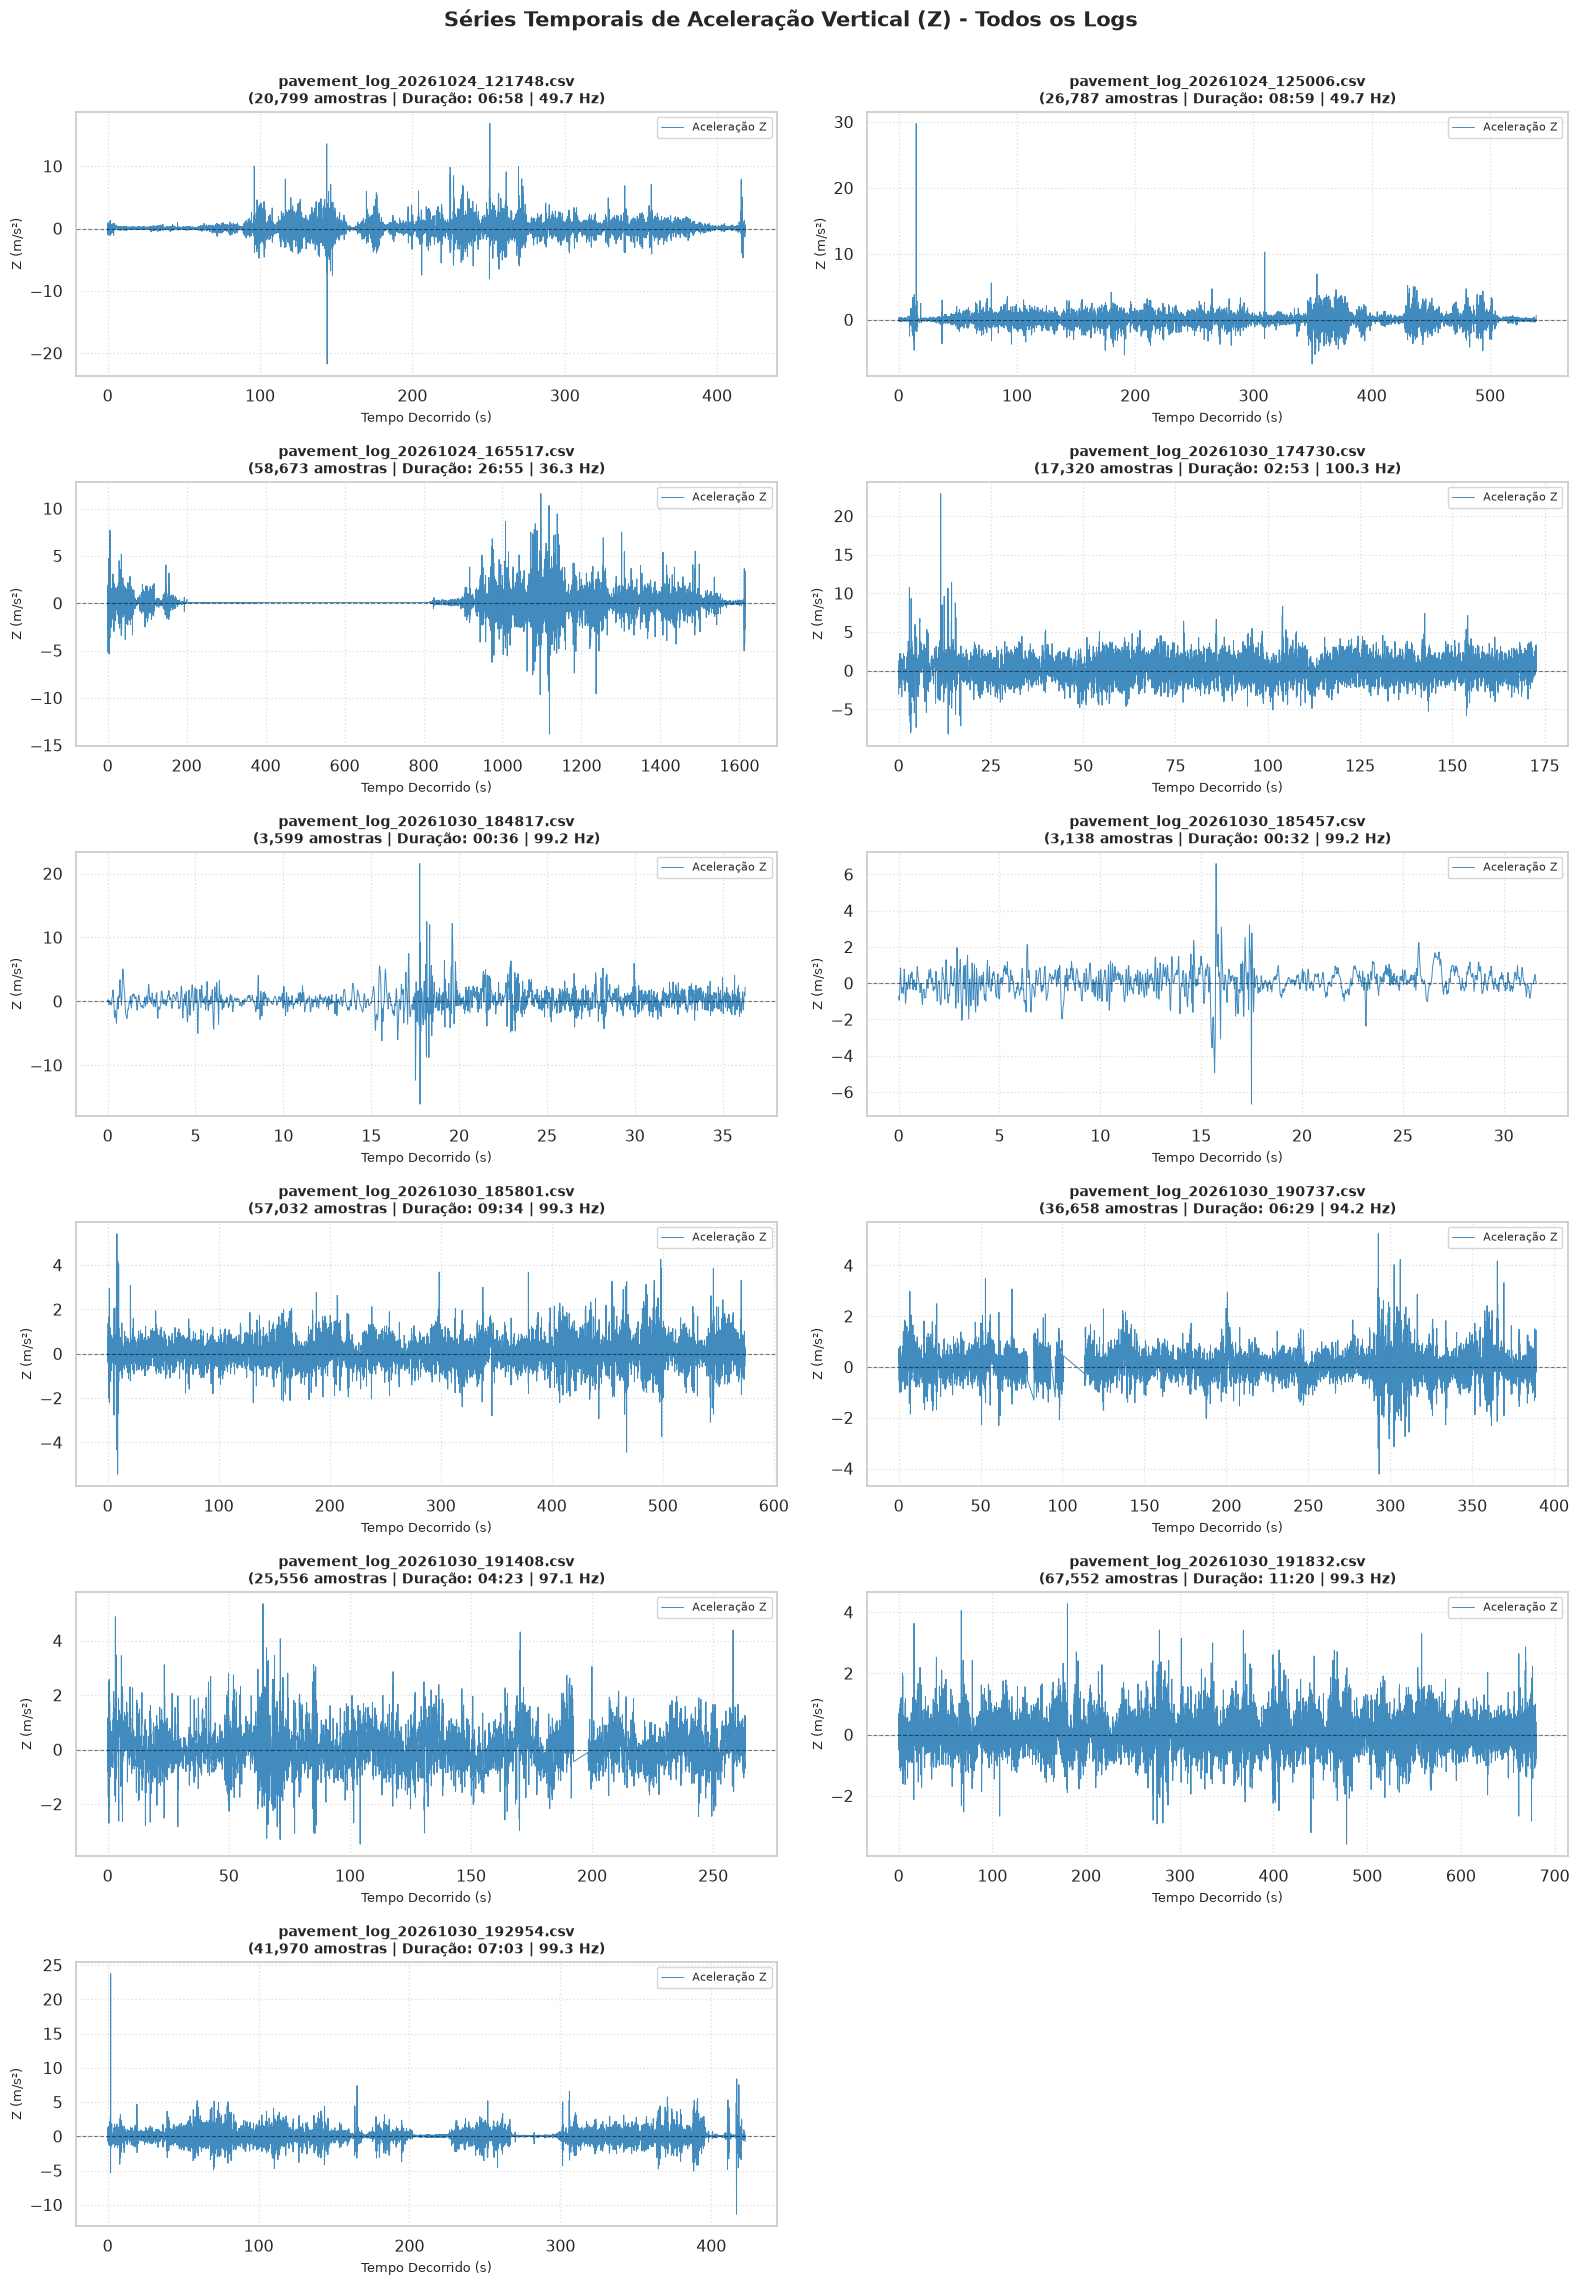

In [4]:
active_logs = summary_df[summary_df["Qtd Amostras"] > 0].reset_index(drop=True)
n_plots = len(active_logs)
n_cols = 2
n_rows = (n_plots + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.8 * n_rows), sharex=False)
axes_flat = axes.flatten()

for idx, row in active_logs.iterrows():
    ax = axes_flat[idx]
    df = load_log(row["Path"])
    
    # Otimização visual para logs com dezenas de milhares de amostras
    if len(df) > 8000:
        step = max(1, len(df) // 8000)
        plot_df = df.iloc[::step]
    else:
        plot_df = df
        
    ax.plot(plot_df["elapsed_sec"], plot_df["z_accel"], color="#1f77b4", linewidth=0.7, alpha=0.85, label="Aceleração Z")
    ax.axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.5)
    
    # Anomalias
    if "is_anomaly" in df.columns and df["is_anomaly"].any():
        anom = df[df["is_anomaly"]]
        ax.scatter(anom["elapsed_sec"], anom["z_accel"], color="red", s=25, label="Anomalia", zorder=5)
        
    title_str = f"{row['Arquivo']}\n({row['Qtd Amostras']:,} amostras | Duração: {row['Duração']} | {row['Freq (Hz)']} Hz)"
    ax.set_title(title_str, fontsize=10, fontweight="bold")
    ax.set_xlabel("Tempo Decorrido (s)", fontsize=9)
    ax.set_ylabel("Z (m/s²)", fontsize=9)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper right", fontsize=8)

# Ocultar eixos vazios na grade
for j in range(n_plots, len(axes_flat)):
    axes_flat[j].set_visible(False)

plt.suptitle("Séries Temporais de Aceleração Vertical (Z) - Todos os Logs", fontsize=15, fontweight="bold", y=1.002)
plt.tight_layout()
plt.show()

---
## 4. Comparativo de Amostras, Duração e Intensidade de Vibração

Comparações entre todas as corridas ativas:
1. **Volume de dados**: Quantidade de amostras por arquivo.
2. **Duração**: Tempo total de monitoramento por sessão.
3. **Rugosidade / Vibração**: Desvio padrão de $Z$ (quanto maior, mais irregular o trecho de pavimento).

/tmp/ipykernel_24510/275238548.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=active_logs, x="Qtd Amostras", y="Arquivo", ax=ax1, palette="Blues_r")
/tmp/ipykernel_24510/275238548.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=active_logs, x="Duração (s)", y="Arquivo", ax=ax2, palette="Greens_r")


/tmp/ipykernel_24510/275238548.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=active_logs, x="Z DesvPad", y="Arquivo", ax=ax3, palette="Oranges_r")


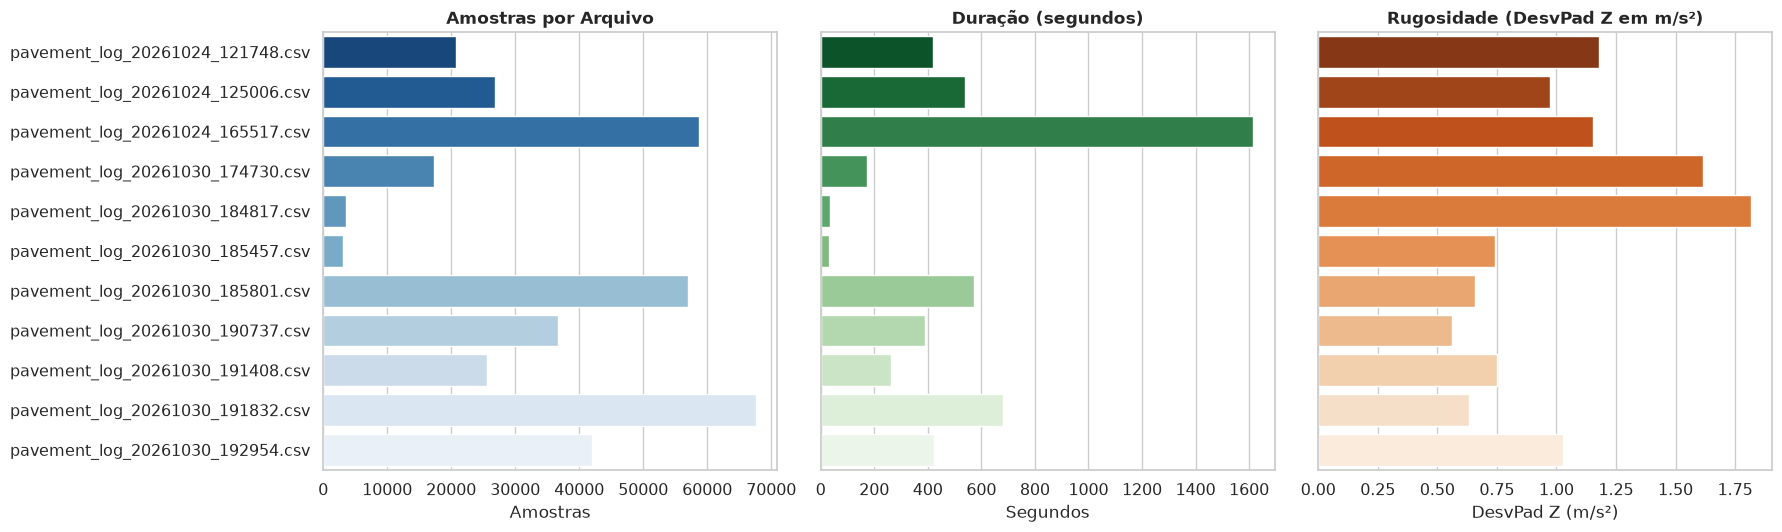

In [5]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Qtd Amostras
sns.barplot(data=active_logs, x="Qtd Amostras", y="Arquivo", ax=ax1, palette="Blues_r")
ax1.set_title("Amostras por Arquivo", fontweight="bold")
ax1.set_xlabel("Amostras")
ax1.set_ylabel("")

# 2. Duração
sns.barplot(data=active_logs, x="Duração (s)", y="Arquivo", ax=ax2, palette="Greens_r")
ax2.set_title("Duração (segundos)", fontweight="bold")
ax2.set_xlabel("Segundos")
ax2.set_ylabel("")
ax2.set_yticklabels([])

# 3. Rugosidade (Desvio Padrão Z)
sns.barplot(data=active_logs, x="Z DesvPad", y="Arquivo", ax=ax3, palette="Oranges_r")
ax3.set_title("Rugosidade (DesvPad Z em m/s²)", fontweight="bold")
ax3.set_xlabel("DesvPad Z (m/s²)")
ax3.set_ylabel("")
ax3.set_yticklabels([])

plt.tight_layout()
plt.show()

---
## 5. Inspeção Detalhada: Aceleração Z vs Velocidade Veicular (GPS)

Análise aprofundada correlacionando aceleração vertical e velocidade para o log de maior extensão com GPS registrado.

Exibindo detalhes para o log com maior amostragem GPS: pavement_log_20261030_191832.csv


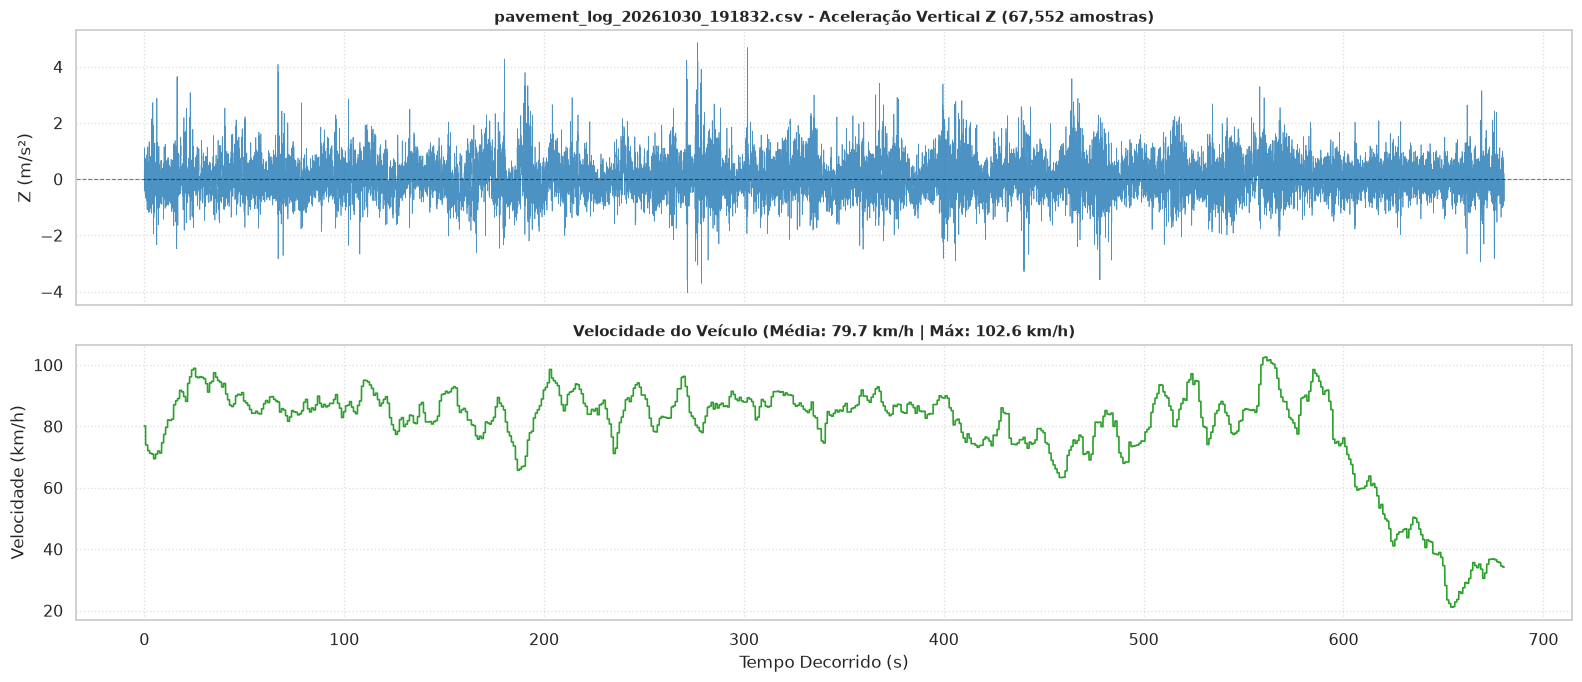

In [6]:
gps_logs = active_logs[active_logs["GPS Válidos"] > 100].sort_values("Qtd Amostras", ascending=False)

if not gps_logs.empty:
    target = gps_logs.iloc[0]
    print(f"Exibindo detalhes para o log com maior amostragem GPS: {target['Arquivo']}")
    df_target = load_log(target["Path"])
    
    fig, (ax_acc, ax_spd) = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
    
    # Série temporal de aceleração Z
    ax_acc.plot(df_target["elapsed_sec"], df_target["z_accel"], color="#1f77b4", linewidth=0.5, alpha=0.8)
    ax_acc.axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.5)
    ax_acc.set_title(f"{target['Arquivo']} - Aceleração Vertical Z ({target['Qtd Amostras']:,} amostras)", fontsize=11, fontweight="bold")
    ax_acc.set_ylabel("Z (m/s²)")
    ax_acc.grid(True, linestyle=":", alpha=0.6)
    
    # Velocidade instantânea (GPS)
    ax_spd.plot(df_target["elapsed_sec"], df_target["speed_kmh"], color="#2ca02c", linewidth=1.2)
    ax_spd.set_title(f"Velocidade do Veículo (Média: {target['Vel Média (km/h)']} km/h | Máx: {target['Vel Máx (km/h)']} km/h)", fontsize=11, fontweight="bold")
    ax_spd.set_xlabel("Tempo Decorrido (s)")
    ax_spd.set_ylabel("Velocidade (km/h)")
    ax_spd.grid(True, linestyle=":", alpha=0.6)
    
    plt.tight_layout()
    plt.show()
else:
    print("Nenhum log com pontos suficientes de GPS encontrado.")